# 07 — Fair AML and graph-learning comparison

Compare persistence, segment-wise multi-output Random Forest, pooled XGBoost, and the trained fixed-graph GAT on the same METR-LA chronological test period. All metrics mask unobserved target speeds. Peak is weekdays 07:00–09:59 and 16:00–18:59; off-peak is all remaining timestamps, including weekends.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
METRICS = ROOT / 'results' / 'metrics'
FIG = ROOT / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

rf = pd.read_csv(METRICS / 'metr_la_baseline_metrics.csv')
xgb = pd.read_csv(METRICS / 'metr_la_xgboost_metrics.csv')
gat = pd.read_csv(METRICS / 'metr_la_gat_metrics.csv')
rf_period = pd.read_csv(METRICS / 'metr_la_baseline_period_metrics.csv')
xgb_period = pd.read_csv(METRICS / 'metr_la_xgboost_period_metrics.csv')
tree_all = pd.concat([rf, xgb], ignore_index=True)
tree_all['period'] = 'All'
all_scores = pd.concat([tree_all, gat], ignore_index=True, sort=False)
period_scores = pd.concat([rf_period, xgb_period, gat[gat['period'] != 'All']], ignore_index=True, sort=False)
scores = pd.concat([all_scores, period_scores], ignore_index=True, sort=False)
scores.to_csv(METRICS / 'metr_la_model_comparison.csv', index=False)
display(scores[['model', 'period', 'horizon_minutes', 'MAE', 'MAPE_percent', 'RMSE', 'valid_test_values']].round(3))

counts = scores.groupby(['period', 'horizon_minutes'])['valid_test_values'].nunique()
assert counts.max() == 1, 'Model scores do not share the same observed target counts by period and horizon.'
print('All models use the same chronological test origins and valid target counts within each period/horizon.')

,model,period,horizon_minutes,MAE,MAPE_percent,RMSE,valid_test_values
0,Persistence,All,5,2.814,6.489,4.627,1244846
1,Random Forest,All,5,2.519,6.327,4.281,1244846
2,Persistence,All,15,3.499,8.612,6.418,1244834
3,Random Forest,All,15,3.119,8.431,5.702,1244834
4,Persistence,All,30,4.207,10.858,8.052,1244816
5,Random Forest,All,30,3.635,10.401,6.706,1244816
6,Persistence,All,60,5.381,14.535,10.345,1244780
7,Random Forest,All,60,4.192,12.623,7.657,1244780
8,XGBoost,All,5,2.554,6.435,4.326,1244846
9,XGBoost,All,15,3.239,8.846,5.873,1244834


All models use the same chronological test origins and valid target counts within each period/horizon.


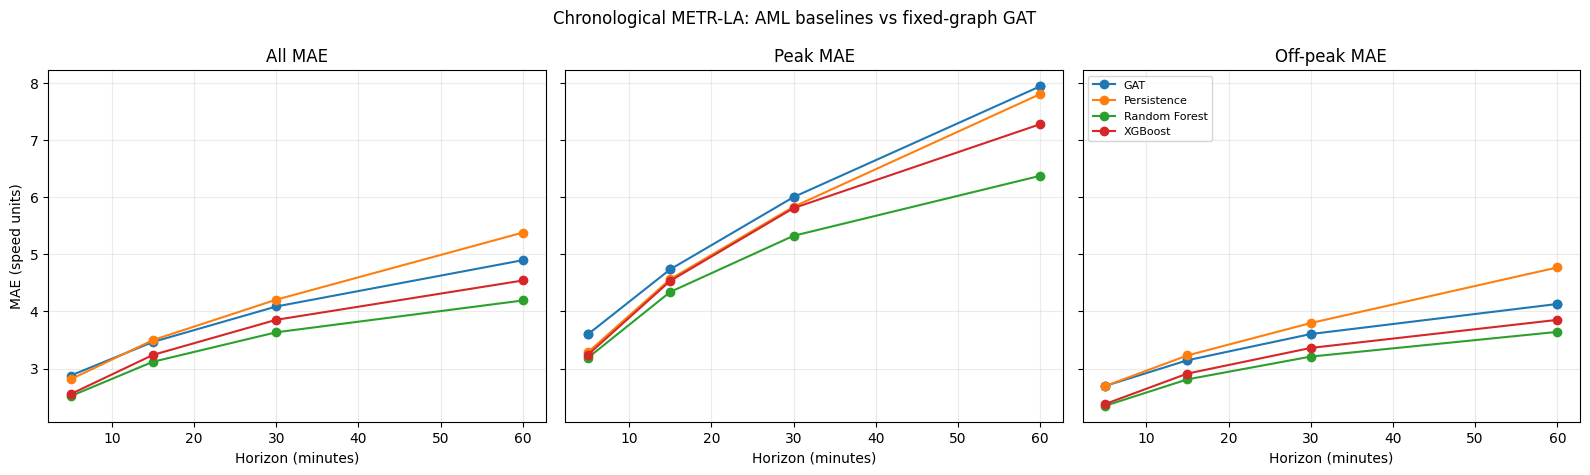

Saved results/figures/27_metr_la_peak_offpeak_model_comparison.png


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, period in zip(axes, ['All', 'Peak', 'Off-peak']):
    view = scores[scores['period'] == period]
    for model, group in view.groupby('model'):
        group = group.sort_values('horizon_minutes')
        ax.plot(group['horizon_minutes'], group['MAE'], marker='o', label=model)
    ax.set(title=f'{period} MAE', xlabel='Horizon (minutes)')
    ax.grid(alpha=.25)
axes[0].set_ylabel('MAE (speed units)')
axes[-1].legend(fontsize=8, loc='upper left')
fig.suptitle('Chronological METR-LA: AML baselines vs fixed-graph GAT')
fig.tight_layout()
fig.savefig(FIG / '27_metr_la_peak_offpeak_model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Saved results/figures/27_metr_la_peak_offpeak_model_comparison.png')